
# Chapter 9: Text Processing and Multiclass Classification

**Book:** scikit-learn Cookbook, Third Edition  
**Author:** John Sukup  
**Publisher:** Packt Publishing (2025)

## Learning Objectives

1. Understand text preprocessing in machine learning.
2. Convert text into numerical features using CountVectorizer and TF-IDF.
3. Extract text features, including n-grams.
4. Implement text classification models.
5. Understand multiclass classification strategies.
6. Evaluate text classification models.

## Chapter Contents

1. Introduction to Text Processing
2. Text Vectorization Techniques
3. Feature Extraction from Text
4. Implementing Text Classification Models
5. Multiclass Classification Strategies
6. Evaluating Text Models
7. Practical Exercises



## 1. Introduction to Text Processing

Text processing merupakan proses mengubah data berbentuk teks menjadi
representasi yang dapat diproses oleh algoritma machine learning.

Data teks sering mengandung tanda baca, perbedaan huruf besar dan kecil,
kata yang berulang, serta informasi yang tidak relevan. Oleh karena itu,
teks perlu dipersiapkan sebelum digunakan untuk melatih model.

Chapter ini menggunakan Natural Language Toolkit (NLTK) untuk mengakses
kumpulan teks atau corpus.

Dataset yang dibahas meliputi:

- **Movie Reviews:** 2.000 ulasan film yang dikategorikan positif atau negatif.
- **Reuters:** kumpulan dokumen berita dengan berbagai kategori topik.
- **Brown Corpus:** kumpulan teks yang dikelompokkan berdasarkan genre.

Tujuan akhirnya adalah mengubah teks menjadi fitur numerik, melatih model,
dan mengevaluasi hasil klasifikasinya.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from nltk.corpus import movie_reviews
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split


In [3]:

# Download corpus jika belum tersedia
try:
    movie_reviews.sents()
except LookupError:
    nltk.download("movie_reviews")

# Mengumpulkan teks ulasan dan label
documents = [
    movie_reviews.raw(file_id)
    for file_id in movie_reviews.fileids()
]

labels = [
    movie_reviews.categories(file_id)[0]
    for file_id in movie_reviews.fileids()
]

# Membagi data menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    documents,
    labels,
    test_size=0.5,
    random_state=2024
)

print("Jumlah seluruh dokumen:", len(documents))
print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))
print("Contoh label:", labels[:5])


[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.


Jumlah seluruh dokumen: 2000
Jumlah data training: 1000
Jumlah data testing: 1000
Contoh label: ['neg', 'neg', 'neg', 'neg', 'neg']



## 2. Text Vectorization Techniques

Komputer tidak bisa langsung menggunakan teks mentah sebagai masukan
untuk sebagian besar algoritma machine learning. Vectorization mengubah
teks menjadi representasi numerik.

### Bag of Words (BoW)

CountVectorizer mengubah teks menjadi matriks jumlah kemunculan kata.
Setiap baris merepresentasikan satu dokumen, sedangkan setiap kolom
merepresentasikan sebuah kata atau token.

Parameter stop_words='english' digunakan untuk menghapus kata umum
berbahasa Inggris yang sering kali kurang membantu proses klasifikasi,
seperti "the", "a", dan "an".


In [4]:

vectorizer = CountVectorizer(stop_words="english")

X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

print("Shape training:", X_train_vect.shape)
print("Shape testing:", X_test_vect.shape)
print("Contoh fitur:", vectorizer.get_feature_names_out()[:20])


Shape training: (1000, 29274)
Shape testing: (1000, 29274)
Contoh fitur: ['00' '000' '0009f' '007' '10' '100' '1000' '10000' '100m' '101' '102'
 '103' '104' '105' '106' '107' '108' '11' '110' '112']


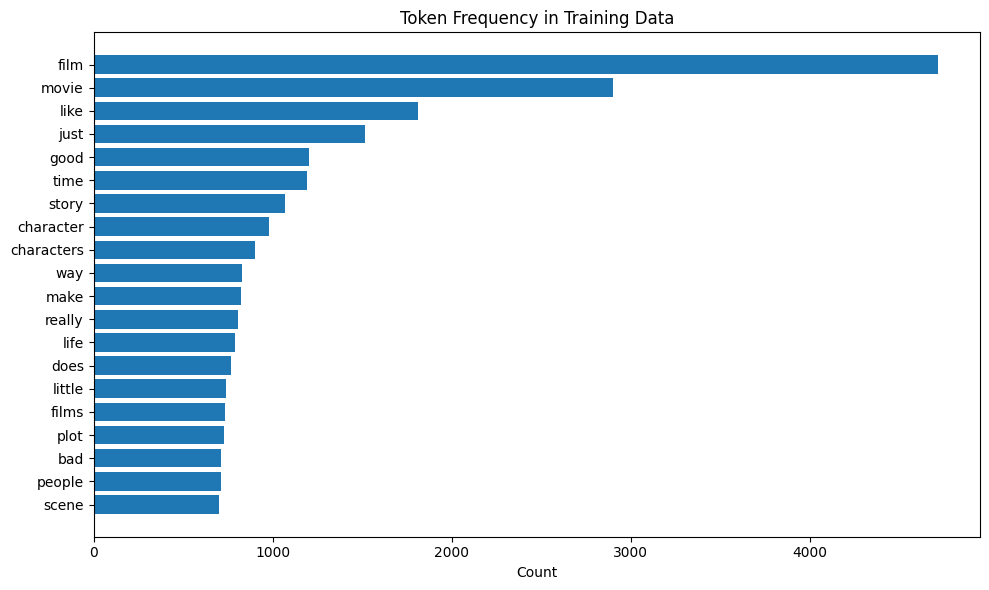

In [5]:

feature_names = vectorizer.get_feature_names_out()
counts = np.asarray(X_train_vect.sum(axis=0)).ravel()

top_indices = np.argsort(counts)[-20:]
top_words = feature_names[top_indices]
top_counts = counts[top_indices]

plt.figure(figsize=(10, 6))
plt.barh(top_words, top_counts)
plt.xlabel("Count")
plt.title("Token Frequency in Training Data")
plt.tight_layout()
plt.show()



### Term Frequency–Inverse Document Frequency (TF-IDF)

TF-IDF memberikan bobot pada kata berdasarkan kemunculannya dalam
suatu dokumen dan seberapa umum kata tersebut di seluruh kumpulan dokumen.

Kata yang sering muncul dalam satu dokumen, tetapi jarang muncul di
dokumen lain, dapat memperoleh bobot lebih tinggi.

Berbeda dengan Bag of Words yang terutama menghitung frekuensi kata,
TF-IDF membantu menonjolkan kata yang lebih khas bagi dokumen tertentu.

Word embeddings merupakan pendekatan lain yang merepresentasikan kata
sebagai vektor padat dan dapat menangkap hubungan semantik. Buku
menjelaskan bahwa embeddings tidak dibuat langsung oleh scikit-learn,
tetapi hasilnya dapat diintegrasikan ke model machine learning.


In [6]:

from nltk.corpus import reuters
from sklearn.feature_extraction.text import TfidfVectorizer

try:
    reuters.fileids()
except LookupError:
    nltk.download("reuters")

documents_reuters = reuters.fileids()

texts_reuters = [
    reuters.raw(doc_id)
    for doc_id in documents_reuters
]

# Buku menggunakan kategori pertama sebagai label
labels_reuters = [
    reuters.categories(doc_id)[0]
    for doc_id in documents_reuters
]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    texts_reuters,
    labels_reuters,
    test_size=0.5,
    random_state=2024
)

tfidf_vectorizer = TfidfVectorizer(stop_words="english")

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_r)
X_test_tfidf = tfidf_vectorizer.transform(X_test_r)

print("Reuters training shape:", X_train_tfidf.shape)
print("Reuters testing shape:", X_test_tfidf.shape)


[nltk_data] Downloading package reuters to /root/nltk_data...


Reuters training shape: (5394, 22581)
Reuters testing shape: (5394, 22581)



## 3. Feature Extraction from Text

Feature extraction bertujuan mendapatkan informasi yang relevan dari
teks untuk membantu model memahami pola data.

### N-grams

N-gram adalah rangkaian token berurutan.

- Unigram: satu kata, misalnya "machine".
- Bigram: dua kata berurutan, misalnya "machine learning".
- Trigram: tiga kata berurutan, misalnya "machine learning model".

Penggunaan n-grams dapat mempertahankan sebagian konteks antarkata,
yang mungkin hilang jika setiap kata dianalisis secara terpisah.


In [7]:

from nltk.corpus import brown
from nltk.util import ngrams as nltk_ngrams
from collections import Counter

try:
    brown.words()
except LookupError:
    nltk.download("brown")

words = [
    word.lower()
    for word in brown.words()
    if word.isalpha()
]

bigram_counts = Counter(nltk_ngrams(words, 2))
trigram_counts = Counter(nltk_ngrams(words, 3))

print("Top 10 bigrams:")
print(bigram_counts.most_common(10))

print("\nTop 10 trigrams:")
print(trigram_counts.most_common(10))


[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.


Top 10 bigrams:
[(('of', 'the'), 9774), (('in', 'the'), 6156), (('to', 'the'), 3525), (('on', 'the'), 2491), (('and', 'the'), 2307), (('for', 'the'), 1862), (('to', 'be'), 1718), (('at', 'the'), 1677), (('with', 'the'), 1545), (('of', 'a'), 1502)]

Top 10 trigrams:
[(('one', 'of', 'the'), 404), (('the', 'united', 'states'), 337), (('as', 'well', 'as'), 238), (('some', 'of', 'the'), 179), (('out', 'of', 'the'), 174), (('the', 'fact', 'that'), 167), (('the', 'end', 'of'), 149), (('part', 'of', 'the'), 146), (('it', 'was', 'a'), 144), (('there', 'was', 'a'), 142)]



## 4. Implementing Text Classification Models

Text classification adalah proses memprediksi kategori suatu dokumen
berdasarkan fitur teksnya.

Alur umum:

1. Menyiapkan teks dan label.
2. Membagi dataset menjadi data training dan testing.
3. Mengubah teks menjadi fitur numerik.
4. Melatih model klasifikasi.
5. Menghasilkan prediksi pada data testing.

Contoh model yang dapat digunakan adalah Logistic Regression dan
Naive Bayes.


In [8]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

text_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", LogisticRegression(max_iter=1000))
])

text_model.fit(X_train, y_train)
y_pred = text_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy: 0.816

Classification Report:
              precision    recall  f1-score   support

         neg       0.81      0.82      0.81       492
         pos       0.83      0.81      0.82       508

    accuracy                           0.82      1000
   macro avg       0.82      0.82      0.82      1000
weighted avg       0.82      0.82      0.82      1000




## 5. Multiclass Classification Strategies

Multiclass classification digunakan ketika target memiliki lebih dari
dua kelas. Contohnya adalah klasifikasi berita Reuters ke dalam kategori
seperti ekonomi, perdagangan, dan komoditas.

Strategi yang dibahas pada bab ini mencakup pendekatan untuk menangani
banyak kelas dengan model klasifikasi. Pemilihan strategi bergantung
pada model yang digunakan dan karakteristik dataset.

Dalam contoh Reuters sebelumnya, label diambil dari kategori pertama
setiap dokumen untuk mengikuti pendekatan yang dijelaskan dalam buku.
Karena itu, hasilnya tidak selalu mencerminkan seluruh kategori yang
dimiliki setiap dokumen Reuters.



## 6. Evaluating Text Models

Evaluasi digunakan untuk mengukur kemampuan model memprediksi kategori
dokumen yang belum digunakan dalam pelatihan.

Metrik yang digunakan antara lain:

- **Accuracy:** proporsi prediksi yang benar.
- **Precision:** proporsi prediksi suatu kelas yang benar.
- **Recall:** proporsi data dari suatu kelas yang berhasil ditemukan.
- **F1-score:** gabungan precision dan recall menggunakan rata-rata
  harmonik.

Untuk dataset dengan jumlah data tiap kelas yang tidak seimbang,
accuracy saja mungkin belum cukup. Oleh sebab itu, precision, recall,
dan F1-score perlu diperiksa bersama-sama.


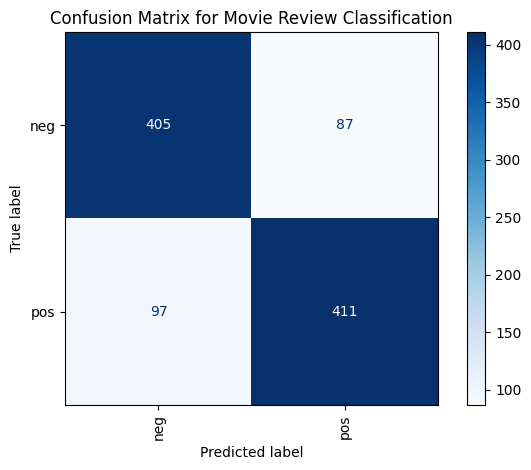

In [9]:

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation="vertical",
    cmap="Blues"
)

plt.title("Confusion Matrix for Movie Review Classification")
plt.tight_layout()
plt.show()



## 7. Summary

Chapter 9 membahas pemrosesan teks dan klasifikasi multiclass
menggunakan scikit-learn.

Poin utama yang dipelajari:

1. Data teks perlu diubah menjadi fitur numerik sebelum digunakan
   oleh model machine learning.
2. CountVectorizer merepresentasikan frekuensi token, sedangkan
   TF-IDF memberikan bobot berdasarkan karakteristik kata dalam dokumen.
3. N-grams membantu merepresentasikan urutan kata.
4. Model klasifikasi dapat dilatih menggunakan fitur hasil vectorization.
5. Evaluasi perlu menggunakan metrik yang sesuai, termasuk accuracy,
   precision, recall, F1-score, dan confusion matrix.

Pemahaman terhadap tahap preprocessing, vectorization, pemodelan,
dan evaluasi menjadi dasar untuk membangun sistem klasifikasi teks
yang lebih andal.
